# Đếm người và khoanh vùng đám đông: MobileCount và MobileCount + Mask (ShanghaiTech Part B)

Notebook cho báo cáo: train **từ đầu** hai model với cùng dữ liệu, cùng quy trình train và cùng cách đánh giá:

1. **MobileCount (baseline):** encoder MobileNetV2 + decoder Light-Weight RefineNet, dự đoán density map.
2. **MobileCount + Mask:** baseline thêm **nhánh mask đám đông**, vừa giảm đếm nhầm ở nền vừa cho bản đồ khoanh vùng đám đông.

Phần cuối là bảng so sánh duy nhất; phân tích và kết luận nằm trong báo cáo.

**Chạy trên Kaggle:** Add Input dataset `tthien/shanghaitech`, bật **GPU**, rồi **Save Version → Save & Run All**. Khoảng 1,5 giờ trên T4 (mỗi model khoảng 45 phút). Trọng số tốt nhất của hai model được lưu ở `/kaggle/working`: `best_mc_baseline_s42_partB.pth` và `best_mc_mask_s42_partB.pth`.

**Nội dung:** 0. Cấu hình → 1. Dữ liệu (EDA) → 2. Density map → 3. Dataset → 4. Kiến trúc → 5. Công cụ train và đánh giá → **6. Train baseline** → **7. Train MobileCount + Mask** → 8. Hình kết quả → 9. Bảng so sánh.

In [1]:
import contextlib, glob, io, json, math, os, random, re, shutil, time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.io as sio
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from IPython.display import display
from PIL import Image, ImageFilter
from scipy.spatial import cKDTree
from torch.utils.data import DataLoader, Dataset

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch', torch.__version__, '| torchvision', torchvision.__version__)
if device.type == 'cuda':
    prop = torch.cuda.get_device_properties(0)
    GPU_NAME = prop.name
    print(f'GPU: {prop.name}, {prop.total_memory / 1024**3:.1f} GB')
else:
    GPU_NAME = 'CPU'
    print('CẢNH BÁO: không có GPU. Vào Settings → Accelerator → chọn GPU.')

plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})
NOTEBOOK_START = time.time()

PyTorch 2.11.0+cu130 | torchvision 0.26.0+cu130
GPU: Tesla T4, 14.6 GB


## 0. Cấu hình

In [2]:
# ---- Dữ liệu ----
PART = 'B'                 # ShanghaiTech Part B: ảnh đường phố, mật độ vừa
DATASET_DIR = '/kaggle/input/datasets/tthien/shanghaitech'
INPUT_DIR, WORK_DIR = '/kaggle/input', '/kaggle/working'
VAL_RATIO = 0.1            # 10% ảnh train tách làm validation (chọn checkpoint)
FIXED_SIGMA = 15           # độ rộng Gaussian (pixel) khi tạo density map ground truth
DENSITY_SCALE = 100.0      # nhân density cho dễ học; số người = tổng density / DENSITY_SCALE
STRIDE = 4                 # density map bằng 1/4 kích thước ảnh
MASK_THRESH = 1e-6         # ô có density GT > ngưỡng = "có người" (nhãn của nhánh mask)

# ---- Train (giống nhau cho cả hai model) ----
SEEDS = [42, 43, 44]
EPOCHS = 400               # train đủ 400 epoch, không dừng sớm
LR, LR_MIN = 1e-4, 1e-6    # learning rate giảm theo cosine từ LR xuống LR_MIN
WEIGHT_DECAY = 1e-4
BATCH_SIZE = 8
CROP = 512                 # cạnh patch cắt ngẫu nhiên từ ảnh train
VAL_EVERY = 5              # đo val MAE mỗi 5 epoch, lưu checkpoint tốt nhất
TRAIN_PROBE = 40           # số ảnh train cố định để đo train MAE (theo dõi overfit)
MASK_LAMBDA = 0.1          # Mask: trọng số loss của nhánh mask
MAX_HOURS_PER_RUN = 1.5    # giới hạn an toàn cho mỗi model
NUM_WORKERS = 4
QUICK = False              # True: chạy thử vài phút (8 ảnh, 2 epoch) để kiểm tra lỗi

# ---- Hai model ----
VARIANTS = {
    'baseline': dict(label='MobileCount (baseline)', backbone='v2', mask=False, aspp=False, aug=False, kd=False),
    'mask':  dict(label='MobileCount + Mask', backbone='v2', mask=True, aspp=False, aug=False, kd=False),
}
RUN_VARIANTS = list(VARIANTS)

# Giá trị kỹ thuật cố định (không cần chỉnh)
ADAPTIVE_BETA, N_SAMPLES, FPS_SIZE, DATA_LIMIT = 0.3, 6, (768, 1024), None
SCHEDULE, KD_ALPHA, teacher, PAPER, NOISE_REL = 'cosine400', 0.0, None, {}, 0.10


def find_data_root(*bases):
    for base in bases:
        for dirpath, dirnames, _ in os.walk(base):
            if 'part_A' in dirnames or 'part_B' in dirnames:
                return dirpath
    raise FileNotFoundError('Không thấy ShanghaiTech: kiểm tra Add Input.')


DATA_ROOT = find_data_root(DATASET_DIR, INPUT_DIR)

if QUICK:
    DATA_LIMIT, EPOCHS, SEEDS, VAL_EVERY, N_SAMPLES, CROP, MAX_HOURS_PER_RUN = 8, 2, [42], 1, 2, 256, 0.1

SIGMA_MODE = 'adaptive' if PART == 'A' else 'fixed'
os.makedirs(WORK_DIR, exist_ok=True)
assert os.path.isdir(os.path.join(DATA_ROOT, f'part_{PART}')), f'Không có part_{PART} trong {DATA_ROOT}'
assert CROP % 32 == 0


def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)


seed_everything(SEEDS[0])
display(pd.DataFrame(VARIANTS).T.loc[RUN_VARIANTS])
print(f'Part {PART} | {EPOCHS} epoch, lr cosine {LR} → {LR_MIN} | patch {CROP} | batch {BATCH_SIZE} | '
      f'seed {SEEDS} → {len(RUN_VARIANTS) * len(SEEDS)} lần train' + (' | CHẾ ĐỘ CHẠY THỬ' if QUICK else ''))

,label,backbone,mask,aspp,aug,kd
baseline,MobileCount (baseline),v2,False,False,False,False
mask,MobileCount + Mask,v2,True,False,False,False


Part B | 400 epoch, lr cosine 0.0001 → 1e-06 | patch 512 | batch 8 | seed [42, 43, 44] → 6 lần train


## 1. Dữ liệu ShanghaiTech

Mỗi ảnh có một file `GT_IMG_x.mat` chứa tọa độ `(x, y)` của từng đầu người. Tập train gốc được tách 10% làm validation (chọn checkpoint); tập test chỉ dùng một lần ở cuối. Cách chia cố định (seed 42) và giống hệt nhau ở cả hai notebook.

In [3]:
def natural_key(path):
    return [int(t) if t.isdigit() else t for t in re.split(r'(\d+)', os.path.basename(path))]


def gt_path(img_path):
    split_dir = os.path.dirname(os.path.dirname(img_path))
    name = 'GT_' + os.path.splitext(os.path.basename(img_path))[0] + '.mat'
    for folder in ('ground-truth', 'ground_truth', 'gt'):
        path = os.path.join(split_dir, folder, name)
        if os.path.exists(path):
            return path
    raise FileNotFoundError(f'Không thấy nhãn cho {img_path}')


def load_points(img_path):
    info = sio.loadmat(gt_path(img_path))['image_info']
    return np.asarray(info[0, 0][0, 0][0], dtype=np.float32).reshape(-1, 2)


def load_split(split):
    pattern = os.path.join(DATA_ROOT, f'part_{PART}', split, 'images', '*.jpg')
    recs = []
    for path in sorted(glob.glob(pattern), key=natural_key)[:DATA_LIMIT]:
        w, h = Image.open(path).size
        recs.append({'name': os.path.basename(path), 'path': path, 'points': load_points(path), 'h': h, 'w': w})
    return recs


def describe(recs):
    c = np.array([len(r['points']) for r in recs])
    return {'số ảnh': len(recs), 'tổng số người': int(c.sum()), 'ít nhất': int(c.min()), 'nhiều nhất': int(c.max()),
            'trung bình': round(c.mean(), 1), 'trung vị': float(np.median(c)), 'độ lệch chuẩn': round(c.std(), 1)}


t0 = time.time()
train_all, test_recs = load_split('train_data'), load_split('test_data')
test_by_name = {r['name']: r for r in test_recs}
order = np.random.RandomState(42).permutation(len(train_all))
n_val = max(1, round(len(train_all) * VAL_RATIO))
val_recs = [train_all[i] for i in sorted(order[:n_val])]
train_recs = [train_all[i] for i in sorted(order[n_val:])]
print(f'Đọc {len(train_all) + len(test_recs)} ảnh và nhãn trong {time.time() - t0:.1f}s')
display(pd.DataFrame({'train': describe(train_recs), 'val': describe(val_recs), 'test': describe(test_recs)}).T)
sizes = pd.Series([f"{r['w']}×{r['h']}" for r in train_all + test_recs]).value_counts()
print(f'Số kích thước ảnh khác nhau: {len(sizes)}; phổ biến nhất: {sizes.index[0]} ({sizes.iloc[0]} ảnh)')

Đọc 716 ảnh và nhãn trong 60.9s


,số ảnh,tổng số người,ít nhất,nhiều nhất,trung bình,trung vị,độ lệch chuẩn
train,360.0,44242.0,12.0,576.0,122.9,101.5,93.9
val,40.0,4909.0,23.0,412.0,122.7,94.0,92.3
test,316.0,39121.0,9.0,539.0,123.8,93.0,95.1


Số kích thước ảnh khác nhau: 1; phổ biến nhất: 1024×768 (716 ảnh)


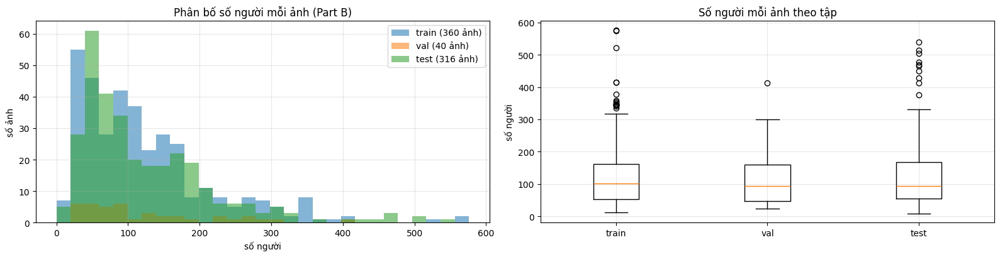

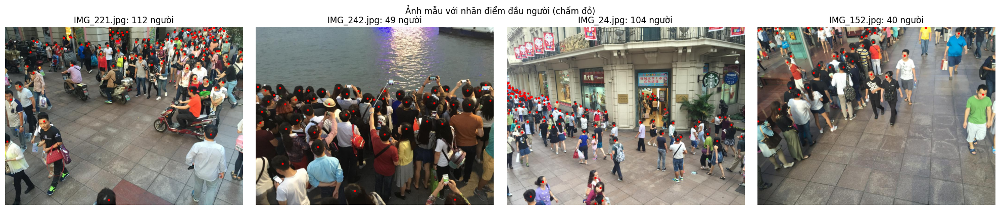

In [4]:
counts = {name: np.array([len(r['points']) for r in recs])
          for name, recs in (('train', train_recs), ('val', val_recs), ('test', test_recs))}
fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
bins = np.linspace(0, max(c.max() for c in counts.values()), 30)
for name, c in counts.items():
    axes[0].hist(c, bins=bins, alpha=0.55, label=f'{name} ({len(c)} ảnh)')
axes[0].set(title=f'Phân bố số người mỗi ảnh (Part {PART})', xlabel='số người', ylabel='số ảnh')
axes[0].legend()
axes[1].boxplot(list(counts.values()))
axes[1].set_xticks(range(1, len(counts) + 1), list(counts.keys()))
axes[1].set(title='Số người mỗi ảnh theo tập', ylabel='số người')
plt.tight_layout(); plt.savefig(os.path.join(WORK_DIR, f'data_stats_part{PART}.png'), bbox_inches='tight'); plt.show()

picks = random.Random(0).sample(train_recs, min(4, len(train_recs)))
fig, axes = plt.subplots(1, len(picks), figsize=(5 * len(picks), 4.2), squeeze=False)
for ax, r in zip(axes[0], picks):
    ax.imshow(Image.open(r['path']).convert('RGB'))
    ax.scatter(r['points'][:, 0], r['points'][:, 1], s=4, c='red')
    ax.set_title(f"{r['name']}: {len(r['points'])} người"); ax.axis('off')
plt.suptitle('Ảnh mẫu với nhãn điểm đầu người (chấm đỏ)'); plt.tight_layout(); plt.show()

### 1.1. Phân tích thêm

- **Vị trí đầu người trên ảnh:** người tập trung ở vùng nào của khung hình (liên quan tới việc chọn vùng giám sát khi triển khai).
- **Khoảng cách tới đầu người gần nhất:** cho biết mức chen chúc, và so với độ rộng Gaussian (`FIXED_SIGMA`) dùng khi tạo density map.
- **Số ảnh theo nhóm mật độ** ở từng tập: các nhóm này được dùng khi phân tích sai số ở phần kết quả.

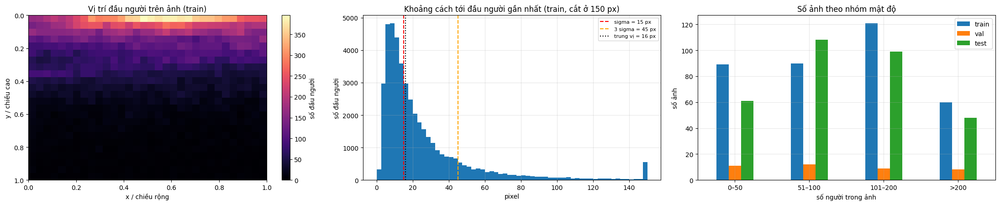

số người,0–50,51–100,101–200,>200
train,89,90,121,60
val,11,12,9,8
test,61,108,99,48


In [5]:
EDA_BINS = {'A': [0, 250, 500, 1000, np.inf], 'B': [0, 50, 100, 200, np.inf]}[PART]
EDA_LABELS = [f'{int(a) + 1 if a else 0}–{int(b)}' if np.isfinite(b) else f'>{int(a)}'
              for a, b in zip(EDA_BINS[:-1], EDA_BINS[1:])]

pos = np.concatenate([r['points'] / [r['w'], r['h']] for r in train_recs if len(r['points'])])
nn_dist = np.concatenate([cKDTree(r['points']).query(r['points'], k=2)[0][:, 1]
                          for r in train_recs if len(r['points']) > 1])

fig, axes = plt.subplots(1, 3, figsize=(22, 4.6))
_, _, _, im = axes[0].hist2d(pos[:, 0], pos[:, 1], bins=[32, 24], range=[[0, 1], [0, 1]], cmap='magma')
axes[0].invert_yaxis(); axes[0].grid(False)
fig.colorbar(im, ax=axes[0], label='số đầu người')
axes[0].set(title='Vị trí đầu người trên ảnh (train)', xlabel='x / chiều rộng', ylabel='y / chiều cao')

axes[1].hist(np.clip(nn_dist, 0, 150), bins=60)
axes[1].axvline(FIXED_SIGMA, color='r', ls='--', label=f'sigma = {FIXED_SIGMA} px')
axes[1].axvline(3 * FIXED_SIGMA, color='orange', ls='--', label=f'3 sigma = {3 * FIXED_SIGMA} px')
axes[1].axvline(np.median(nn_dist), color='k', ls=':', label=f'trung vị = {np.median(nn_dist):.0f} px')
axes[1].set(title='Khoảng cách tới đầu người gần nhất (train, cắt ở 150 px)', xlabel='pixel', ylabel='số đầu người')
axes[1].legend(fontsize=8)

groups = pd.DataFrame({name: pd.cut(pd.Series([len(r['points']) for r in recs]), EDA_BINS, labels=EDA_LABELS,
                                    include_lowest=True).value_counts().reindex(EDA_LABELS)
                       for name, recs in (('train', train_recs), ('val', val_recs), ('test', test_recs))})
groups.plot.bar(ax=axes[2], rot=0)
axes[2].set(title='Số ảnh theo nhóm mật độ', xlabel='số người trong ảnh', ylabel='số ảnh')
plt.tight_layout(); plt.savefig(os.path.join(WORK_DIR, f'eda_part{PART}.png'), bbox_inches='tight'); plt.show()
display(groups.rename_axis('số người').T)

## 2. Density map ground truth và vùng "có người"

- **Density map:** một Gaussian tại mỗi đầu người, cắt ở bán kính 3 sigma và chuẩn hóa để tổng bằng 1 cho mỗi người (Part B: sigma 15 px; Part A: sigma thích nghi). Khi train, density được cộng gộp xuống 1/4 cho khớp đầu ra của MobileCount.
- **Vùng "có người":** các ô density 1/4 lớn hơn `MASK_THRESH`, tức nằm trong bán kính 3 sigma của ít nhất một đầu người. Phần còn lại là **nền**: ở đó density ground truth bằng đúng 0.

Vùng này dùng để đo **đếm nhầm ở nền** (tổng density dự đoán rơi vào nền, tức chỗ cách mọi đầu người hơn 3 sigma), và làm nhãn cho nhánh mask. Ngưỡng được chọn để phủ trọn Gaussian: nếu ngưỡng cao hơn, phần đuôi Gaussian rơi ra "nền", khiến cả model hoàn hảo cũng bị tính là đếm nhầm.

In [6]:
_KERNELS = {}


def gaussian_kernel(sigma):
    key = round(float(sigma), 1)
    if key not in _KERNELS:
        r = max(1, int(math.ceil(3 * key)))
        ax = np.arange(-r, r + 1, dtype=np.float32)
        g = np.exp(-ax ** 2 / (2 * key ** 2))
        k = np.outer(g, g)
        _KERNELS[key] = (k / k.sum()).astype(np.float32)
    return _KERNELS[key]


def point_sigmas(points):
    if SIGMA_MODE == 'fixed' or len(points) < 4:
        return np.full(len(points), FIXED_SIGMA, np.float32)
    dist, _ = cKDTree(points).query(points, k=4)
    return np.clip(ADAPTIVE_BETA * dist[:, 1:].mean(axis=1), 1.0, 3 * FIXED_SIGMA)


def make_density(points, h, w):
    """Mỗi người là một Gaussian có tổng bằng 1, nên tổng density = số người."""
    den = np.zeros((h, w), np.float32)
    for (x, y), s in zip(points, point_sigmas(points)):
        x, y = min(max(int(x), 0), w - 1), min(max(int(y), 0), h - 1)
        k = gaussian_kernel(s)
        r = k.shape[0] // 2
        y0, y1, x0, x1 = max(y - r, 0), min(y + r + 1, h), max(x - r, 0), min(x + r + 1, w)
        patch = k[y0 - y + r:y1 - y + r, x0 - x + r:x1 - x + r]
        den[y0:y1, x0:x1] += patch / patch.sum()
    return den


def sum_pool(den, s):
    """Thu nhỏ density s lần mỗi chiều bằng cách cộng từng ô s×s (giữ nguyên tổng)."""
    h, w = den.shape
    H, W = math.ceil(h / s) * s, math.ceil(w / s) * s
    den = np.pad(den, ((0, H - h), (0, W - w)))
    return den.reshape(H // s, s, W // s, s).sum(axis=(1, 3))


t0 = time.time()
densities = {r['name']: make_density(r['points'], r['h'], r['w']) for r in train_all}
GT_TEST = {r['name']: sum_pool(make_density(r['points'], r['h'], r['w']), STRIDE) for r in test_recs}
print(f'Tạo density cho {len(densities)} ảnh train và {len(GT_TEST)} ảnh test trong {time.time() - t0:.1f}s')
print(f"Sai lệch lớn nhất giữa tổng density và số nhãn: "
      f"{max(abs(densities[r['name']].sum() - len(r['points'])) for r in train_all):.4f} người")
cover = [(g > MASK_THRESH).mean() for g in GT_TEST.values()]
leak = [g[g <= MASK_THRESH].sum() for g in GT_TEST.values()]
print(f'Vùng "có người" chiếm trung bình {np.mean(cover):.1%} diện tích ảnh test (ít nhất {np.min(cover):.1%}, '
      f'nhiều nhất {np.max(cover):.1%}); density GT nằm ngoài vùng này: {max(leak):.6f} người (phải bằng 0)')

Tạo density cho 400 ảnh train và 316 ảnh test trong 4.6s
Sai lệch lớn nhất giữa tổng density và số nhãn: 0.0004 người
Vùng "có người" chiếm trung bình 34.5% diện tích ảnh test (ít nhất 9.5%, nhiều nhất 65.7%); density GT nằm ngoài vùng này: 0.000057 người (phải bằng 0)


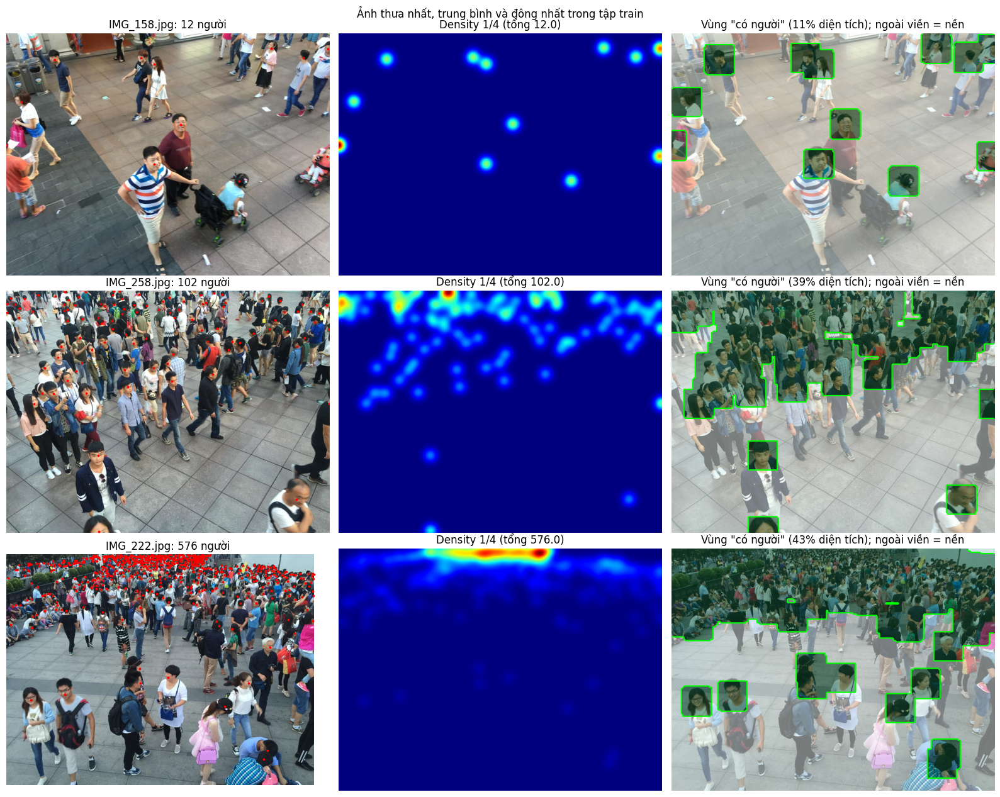

In [7]:
picks = sorted(train_recs, key=lambda r: len(r['points']))
picks = [picks[0], picks[len(picks) // 2], picks[-1]]
fig, axes = plt.subplots(len(picks), 3, figsize=(16, 4.3 * len(picks)), squeeze=False)
for row, r in zip(axes, picks):
    img = Image.open(r['path']).convert('RGB')
    small = sum_pool(densities[r['name']], STRIDE)
    mask = small > MASK_THRESH
    extent = (0, small.shape[1] * STRIDE, small.shape[0] * STRIDE, 0)
    row[0].imshow(img); row[0].scatter(r['points'][:, 0], r['points'][:, 1], s=3, c='red')
    row[0].set_title(f"{r['name']}: {len(r['points'])} người")
    row[1].imshow(small, cmap='jet'); row[1].set_title(f'Density 1/4 (tổng {small.sum():.1f})')
    row[2].imshow(img); row[2].imshow(mask, cmap='Greens', alpha=0.45, extent=extent)
    row[2].contour(mask, levels=[0.5], colors='lime', linewidths=1.5, extent=extent, origin='upper')
    row[2].set(xlim=(0, img.size[0]), ylim=(img.size[1], 0))
    row[2].set_title(f'Vùng "có người" ({mask.mean():.0%} diện tích); ngoài viền = nền')
    for ax in row:
        ax.axis('off')
plt.suptitle('Ảnh thưa nhất, trung bình và đông nhất trong tập train'); plt.tight_layout(); plt.show()

## 3. Dataset

Mỗi lần lấy một ảnh: cắt ngẫu nhiên một patch, lật ngang với xác suất 50%, chuẩn hóa màu theo ImageNet. Mỗi patch đi kèm density 1/4 và nhãn vùng "có người" (dùng cho nhánh mask). Hai phiên bản dùng chung dataset này.

In [8]:
MEAN = np.array([0.485, 0.456, 0.406], np.float32)
STD = np.array([0.229, 0.224, 0.225], np.float32)


class CrowdPatches(Dataset):
    """Trả về (ảnh, density 1/4 đã nhân DENSITY_SCALE, vùng "có người" 1/4)."""

    def __init__(self, recs, densities, aug=False):
        self.recs, self.densities, self.aug = recs, densities, aug

    def __len__(self):
        return len(self.recs)

    def __getitem__(self, i):
        r = self.recs[i]
        img, den = Image.open(r['path']).convert('RGB'), self.densities[r['name']]
        arr = np.asarray(img, np.float32) / 255.0
        h, w = den.shape
        y, x = random.randint(0, max(h - CROP, 0)), random.randint(0, max(w - CROP, 0))
        arr, den = arr[y:y + CROP, x:x + CROP], den[y:y + CROP, x:x + CROP]
        arr = (arr - MEAN) / STD
        ph, pw = CROP - den.shape[0], CROP - den.shape[1]
        if ph or pw:
            arr = np.pad(arr, ((0, ph), (0, pw), (0, 0)))
            den = np.pad(den, ((0, ph), (0, pw)))
        if random.random() < 0.5:
            arr, den = arr[:, ::-1], den[:, ::-1]
        small = sum_pool(den, STRIDE)
        return (torch.from_numpy(np.ascontiguousarray(arr.transpose(2, 0, 1), dtype=np.float32)),
                torch.from_numpy(np.ascontiguousarray(small[None] * DENSITY_SCALE, dtype=np.float32)),
                torch.from_numpy(np.ascontiguousarray((small > MASK_THRESH)[None], dtype=np.float32)))


def make_loader(aug=False):
    return DataLoader(CrowdPatches(train_recs, densities, aug), batch_size=BATCH_SIZE, shuffle=True,
                      drop_last=len(train_recs) >= BATCH_SIZE, num_workers=NUM_WORKERS,
                      pin_memory=device.type == 'cuda', persistent_workers=NUM_WORKERS > 0)


def denormalize(chw):
    return np.clip(chw.transpose(1, 2, 0) * STD + MEAN, 0, 1)

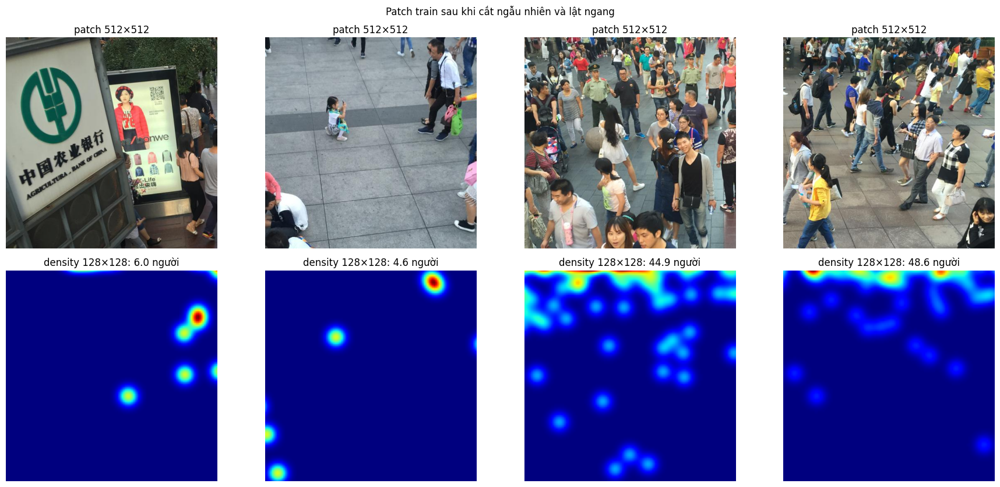

In [9]:
seed_everything(SEEDS[0])
ds = CrowdPatches(train_recs, densities)
n_show = min(4, len(train_recs))
fig, axes = plt.subplots(2, n_show, figsize=(4.5 * n_show, 8.5), squeeze=False)
for j in range(n_show):
    img, den, _ = ds[j]
    axes[0, j].imshow(denormalize(img.numpy())); axes[0, j].set_title(f'patch {CROP}×{CROP}')
    axes[1, j].imshow(den[0].numpy(), cmap='jet')
    axes[1, j].set_title(f'density {den.shape[-1]}×{den.shape[-2]}: {den.sum() / DENSITY_SCALE:.1f} người')
    for ax in axes[:, j]:
        ax.axis('off')
plt.suptitle('Patch train sau khi cắt ngẫu nhiên và lật ngang'); plt.tight_layout(); plt.show()

## 4. Kiến trúc

```
Ảnh → MobileNetV2 (đặc trưng 1/4, 1/8, 1/16, 1/32)
        1/32 → conv 1×1 → CRP ─┐
        1/16 → conv 1×1 ── + ← phóng to → CRP ─┐
        1/8  → conv 1×1 ── + ← phóng to → CRP ─┐
        1/4  → conv 1×1 ── + ← phóng to → CRP → Y
Y ─┬→ head density → D
   └→ [Mask: head mask → M = sigmoid(·)]        Đầu ra = D × M (baseline: D)
```

- **Baseline MobileCount:** encoder MobileNetV2 pretrained ImageNet, decoder Light-Weight RefineNet (CRP: chuỗi max pool 5×5 + conv 1×1), đầu ra density 1/4 kích thước ảnh. Số người = tổng density.
- **MobileCount + Mask (nhánh mask đám đông):** thêm một head nhỏ (2 lớp conv) dự đoán xác suất mỗi ô 4×4 pixel thuộc vùng có người. Density cuối = D × M, nên density ở nền bị triệt tiêu. Loss = MSE(D × M, density GT) + `MASK_LAMBDA` × BCE(M, nhãn vùng "có người"). Nhãn mask tạo tự động từ density GT, không cần gán nhãn thêm. Khi triển khai, M là bản đồ khoanh vùng đám đông.

In [10]:
class ChainedResidualPool(nn.Module):
    """Chuỗi max pool 5×5 + conv 1×1 cộng dồn: gom ngữ cảnh rộng với rất ít tham số (Light-Weight RefineNet)."""

    def __init__(self, channels, n_stages=4):
        super().__init__()
        self.pool = nn.MaxPool2d(5, stride=1, padding=2)
        self.convs = nn.ModuleList([nn.Conv2d(channels, channels, 1, bias=False) for _ in range(n_stages)])

    def forward(self, x):
        top = x
        for conv in self.convs:
            top = conv(self.pool(top))
            x = x + top
        return x


class ASPP(nn.Module):
    """C2: ngữ cảnh đa tỉ lệ bằng các nhánh dilation 1, 2, 4 và một nhánh pooling toàn ảnh."""

    def __init__(self, cin, cout, rates=(1, 2, 4)):
        super().__init__()
        self.branches = nn.ModuleList([
            nn.Sequential(nn.Conv2d(cin, cout, 1 if r == 1 else 3, padding=0 if r == 1 else r, dilation=r, bias=False),
                          nn.ReLU(inplace=True)) for r in rates])
        self.image_pool = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(cin, cout, 1, bias=False), nn.ReLU(inplace=True))
        self.merge = nn.Sequential(nn.Conv2d(cout * (len(rates) + 1), cout, 1, bias=False), nn.ReLU(inplace=True))

    def forward(self, x):
        feats = [b(x) for b in self.branches]
        feats.append(F.interpolate(self.image_pool(x), size=x.shape[-2:], mode='bilinear', align_corners=False))
        return self.merge(torch.cat(feats, dim=1))


def make_encoder(backbone, pretrained):
    """4 mức đặc trưng 1/4, 1/8, 1/16, 1/32 và số kênh của từng mức."""
    if backbone == 'v3':   # MobileNetV3-Large (không dùng ở notebook này)
        weights = torchvision.models.MobileNet_V3_Large_Weights.IMAGENET1K_V2 if pretrained else None
        f = torchvision.models.mobilenet_v3_large(weights=weights).features
        return nn.ModuleList([f[:4], f[4:7], f[7:13], f[13:16]]), (24, 40, 112, 160)
    weights = torchvision.models.MobileNet_V2_Weights.IMAGENET1K_V1 if pretrained else None
    f = torchvision.models.mobilenet_v2(weights=weights).features
    return nn.ModuleList([f[:4], f[4:7], f[7:14], f[14:18]]), (24, 32, 96, 320)


class ImprovedMobileCount(nn.Module):
    """MobileCount, tùy chọn nhánh mask đám đông (mask=True). Tắt mask thì đúng là baseline."""

    def __init__(self, pretrained=True, mask=False, aspp=False, backbone='v2', channels=64):
        super().__init__()
        self.encoder, enc_ch = make_encoder(backbone, pretrained)
        self.project = nn.ModuleList([nn.Conv2d(c, channels, 1, bias=False) for c in enc_ch[:3]])
        self.deep = ASPP(enc_ch[3], channels) if aspp else nn.Sequential(
            nn.Conv2d(enc_ch[3], channels, 1, bias=False), nn.ReLU(inplace=True))
        self.crp = nn.ModuleList([ChainedResidualPool(channels) for _ in range(4)])
        self.fuse = nn.ModuleList([nn.Conv2d(channels, channels, 1, bias=False) for _ in range(3)])
        self.head = nn.Sequential(nn.Conv2d(channels, channels, 3, padding=1), nn.ReLU(inplace=True),
                                  nn.Conv2d(channels, 1, 1))
        self.mask_head = None
        if mask:
            self.mask_head = nn.Sequential(nn.Conv2d(channels, 32, 3, padding=1), nn.ReLU(inplace=True),
                                           nn.Conv2d(32, 1, 1))
            nn.init.constant_(self.mask_head[-1].bias, 1.0)

    def forward(self, x, with_mask=False):
        feats = []
        for stage in self.encoder:
            x = stage(x)
            feats.append(x)
        y = self.crp[3](self.deep(feats[3]))
        for i in (2, 1, 0):
            y = F.interpolate(self.fuse[i](y), size=feats[i].shape[-2:], mode='bilinear', align_corners=False)
            y = self.crp[i](F.relu(self.project[i](feats[i]) + y))
        den = self.head(y)
        if self.mask_head is None:
            return (den, None) if with_mask else den
        logit = self.mask_head(y)
        den = den * torch.sigmoid(logit)
        return (den, logit) if with_mask else den


def build_variant(key, pretrained=True):
    cfg = VARIANTS[key]
    return ImprovedMobileCount(pretrained=pretrained, mask=cfg['mask'], aspp=cfg['aspp'],
                               backbone=cfg['backbone']).to(device)

In [11]:
def sync():
    if device.type == 'cuda':
        torch.cuda.synchronize()


@torch.no_grad()
def measure_fps(model, size, half=False, runs=30):
    x = torch.randn(1, 3, *size, device=device)
    ctx = torch.autocast('cuda', dtype=torch.float16) if half and device.type == 'cuda' else contextlib.nullcontext()
    with ctx:
        for _ in range(5):
            model(x)
        sync(); t = time.perf_counter()
        for _ in range(runs):
            model(x)
        sync()
    return runs / (time.perf_counter() - t)


@torch.no_grad()
def count_gmacs(model, size):
    try:
        from torch.utils.flop_counter import FlopCounterMode
        with FlopCounterMode(display=False) as counter:
            model(torch.zeros(1, 3, *size, device=device))
        return counter.get_total_flops() / 2e9
    except Exception as e:
        print('  không đo được FLOPs:', e)
        return None


def model_stats(model):
    model.eval()
    return {'params_M': sum(p.numel() for p in model.parameters()) / 1e6, 'GMACs': count_gmacs(model, FPS_SIZE),
            'FPS': measure_fps(model, FPS_SIZE), 'FPS_fp16': measure_fps(model, FPS_SIZE, half=True)}


MODEL_STATS = {}
for key in RUN_VARIANTS:
    model = build_variant(key).eval()
    with torch.no_grad():
        out = model(torch.zeros(1, 3, CROP, CROP, device=device))
    assert out.shape[-2:] == (CROP // STRIDE, CROP // STRIDE), f'{key}: kích thước đầu ra sai {tuple(out.shape)}'
    MODEL_STATS[key] = model_stats(model)
    del model
if device.type == 'cuda':
    torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 109MB/s] 


## 5. Công cụ train và đánh giá

Giống nhau cho cả hai model.

- **Train:** Adam, mixed precision. Mỗi `VAL_EVERY` epoch đo MAE trên validation; checkpoint có **val MAE thấp nhất** là kết quả chính. Tập test không tham gia vào việc chọn checkpoint.
- **Learning rate cosine, không dừng sớm:** lr giảm dần theo cosine từ `LR` xuống `LR_MIN`, mọi phiên bản train đủ `EPOCHS` epoch. Cùng thời lượng train thì so sánh giữa các phiên bản mới công bằng.
- **Hai checkpoint:** checkpoint val MAE tốt nhất (kết quả chính) và checkpoint epoch cuối đều được đánh giá trên test. Hai số gần nhau nghĩa là việc chọn theo tập val nhỏ (40 ảnh) không làm kết quả bị may rủi.
- **Theo dõi overfit:** mỗi lần đo val, notebook đo thêm MAE trên `TRAIN_PROBE` ảnh train cố định. Biểu đồ vẽ train MAE (nét đứt) cạnh val MAE: khoảng cách giữa hai đường tăng dần là dấu hiệu overfit.
- **Số seed:** mặc định 1 seed (`SEEDS = [42]`). Kết quả một lần train có dao động ngẫu nhiên, nên khi so sánh, chênh lệch dưới `NOISE_REL` (10%) được coi là dao động. Thêm seed 43, 44 thì kết quả báo cáo dạng trung bình ± độ lệch chuẩn.
- **Đánh giá test** trên ảnh kích thước gốc:
  - **MAE, MSE** (theo quy ước của lĩnh vực đếm người, MSE thực chất là căn bậc hai sai số bình phương trung bình).
  - **GAME(L):** chia ảnh thành lưới 2^L × 2^L ô, cộng sai số đếm từng ô; đo cả việc đếm đúng chỗ.
  - **Đếm nhầm ở nền:** tổng density dự đoán ở các ô cách mọi đầu người hơn 3 sigma.
  - **IoU mask** (chỉ MobileCount + Mask): độ trùng giữa vùng đám đông dự đoán và thực tế.

In [12]:
BINS = {'A': [0, 250, 500, 1000, np.inf], 'B': [0, 50, 100, 200, np.inf]}
BIN_LABELS = [f'{int(a) + 1 if a else 0}–{int(b)}' if np.isfinite(b) else f'>{int(a)}'
              for a, b in zip(BINS[PART][:-1], BINS[PART][1:])]
METRICS = ['MAE', 'MSE', 'GAME1', 'GAME2', 'GAME3', 'Đếm nhầm ở nền', 'IoU mask']


def density_bin(gt):
    return pd.cut(gt, BINS[PART], labels=BIN_LABELS, include_lowest=True)


@torch.no_grad()
def predict(model, path, stride=STRIDE, with_mask=False):
    """Density dự đoán (đã chia DENSITY_SCALE) và mask xác suất (nếu có) cho cả ảnh."""
    img = (np.asarray(Image.open(path).convert('RGB'), np.float32) / 255.0 - MEAN) / STD
    h, w, _ = img.shape
    H, W = math.ceil(h / 32) * 32, math.ceil(w / 32) * 32
    img = np.pad(img, ((0, H - h), (0, W - w), (0, 0)))
    x = torch.from_numpy(np.ascontiguousarray(img.transpose(2, 0, 1)))[None].to(device)
    hh, ww = math.ceil(h / stride), math.ceil(w / stride)
    if with_mask:
        den, logit = model(x, with_mask=True)
        mask = None if logit is None else torch.sigmoid(logit)[0, 0].float().cpu().numpy()[:hh, :ww]
    else:
        den, mask = model(x), None
    return den[0, 0].float().cpu().numpy()[:hh, :ww] / DENSITY_SCALE, mask


def evaluate_counts(model, recs):
    was_training = model.training
    model.eval()
    err = np.array([predict(model, r['path'])[0].sum() - len(r['points']) for r in recs])
    model.train(was_training)
    return {'MAE': float(np.abs(err).mean()), 'MSE': float(np.sqrt((err ** 2).mean()))}


def game(pred, gt, level):
    n = 2 ** level
    return sum(abs(p2.sum() - g2.sum())
               for p1, g1 in zip(np.array_split(pred, n, 0), np.array_split(gt, n, 0))
               for p2, g2 in zip(np.array_split(p1, n, 1), np.array_split(g1, n, 1)))


def evaluate_full(model, recs, stride=STRIDE, with_mask=False):
    model.eval()
    rows = []
    for r in recs:
        gt = GT_TEST[r['name']] if stride == STRIDE else sum_pool(GT_TEST[r['name']], stride // STRIDE)
        pred, mask = predict(model, r['path'], stride, with_mask)
        background = gt <= MASK_THRESH
        row = {'name': r['name'], 'gt': len(r['points']), 'pred': float(pred.sum()),
               'bg_count': float(np.clip(pred, 0, None)[background].sum())}
        for level in (1, 2, 3):
            row[f'GAME{level}'] = float(game(pred, gt, level))
        if mask is not None:
            m, g = mask > 0.5, ~background
            row['mask_iou'] = float((m & g).sum() / max((m | g).sum(), 1))
        rows.append(row)
    df = pd.DataFrame(rows)
    df['error'] = df['pred'] - df['gt']
    return df


def summarize(df):
    out = {'MAE': df['error'].abs().mean(), 'MSE': np.sqrt((df['error'] ** 2).mean()),
           **{f'GAME{l}': df[f'GAME{l}'].mean() for l in (1, 2, 3)}, 'Đếm nhầm ở nền': df['bg_count'].mean()}
    if 'mask_iou' in df:
        out['IoU mask'] = df['mask_iou'].mean()
    return {k: float(v) for k, v in out.items()}


def make_scaler(enabled):
    try:
        return torch.amp.GradScaler('cuda', enabled=enabled)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=enabled)


def files_of(key, seed):
    tag = f'mc_{key}_s{seed}_part{PART}'
    return {'results': f'results_{tag}.json', 'preds': f'preds_{tag}.csv', 'history': f'history_{tag}.csv',
            'samples': f'samples_{tag}.npz', 'weights': f'best_{tag}.pth', 'last': f'last_{tag}.pth'}


def load_record(key, seed, folder=WORK_DIR):
    f = {k: os.path.join(folder, v) for k, v in files_of(key, seed).items()}
    with open(f['results'], encoding='utf-8') as fh:
        res = json.load(fh)
    with np.load(f['samples']) as s:
        samples = {k: s[k] for k in s.files}
    return {'res': res, 'preds': pd.read_csv(f['preds']), 'history': pd.read_csv(f['history']),
            'samples': samples, 'weights': f['weights']}


def mean_std(key, metric):
    vals = [r['res'][metric] for r in RESULTS.get(key, []) if metric in r['res']]
    if not vals:
        return np.nan, np.nan
    return float(np.mean(vals)), float(np.std(vals, ddof=1)) if len(vals) > 1 else 0.0


def fmt_ms(mu, sd):
    if np.isnan(mu):
        return '–'
    return f'{mu:.2f} ± {sd:.2f}' if len(SEEDS) > 1 else f'{mu:.2f}'


def mean_preds(key):
    """Dự đoán trung bình qua các seed cho từng ảnh test."""
    df = pd.concat([r['preds'] for r in RESULTS[key]])
    cols = [c for c in ('pred', 'bg_count', 'mask_iou') if c in df]
    out = df.groupby('name').agg({'gt': 'first', **{c: 'mean' for c in cols}})
    out['error'] = out['pred'] - out['gt']
    return out


SAMPLE_NAMES = [test_recs[i]['name'] for i in np.linspace(0, len(test_recs) - 1, N_SAMPLES).astype(int)]
RESULTS = {}

In [13]:
train_probe = random.Random(0).sample(train_recs, min(TRAIN_PROBE, len(train_recs)))


def train_once(key, seed):
    cfg, files = VARIANTS[key], {k: os.path.join(WORK_DIR, v) for k, v in files_of(key, seed).items()}
    seed_everything(seed)
    model = build_variant(key)
    loader = make_loader(cfg['aug'])
    use_teacher = teacher if cfg['kd'] else None
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=LR_MIN)
    use_amp = device.type == 'cuda'
    scaler = make_scaler(use_amp)

    history, best_mae, best_epoch = [], float('inf'), 0
    start = time.time()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        t_epoch, parts = time.time(), {'loss': [], 'loss_density': [], 'loss_mask': [], 'loss_kd': []}
        for img, den, mask_gt in loader:
            img, den, mask_gt = (t.to(device, non_blocking=True) for t in (img, den, mask_gt))
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                out, logit = model(img, with_mask=True)
                target = use_teacher(img) if use_teacher is not None else None
            out = out.float()
            loss = F.mse_loss(out, den)
            parts['loss_density'].append(loss.item())
            if logit is not None:
                l_mask = F.binary_cross_entropy_with_logits(logit.float(), mask_gt)
                loss = loss + MASK_LAMBDA * l_mask
                parts['loss_mask'].append(l_mask.item())
            if target is not None:
                l_kd = F.mse_loss(F.avg_pool2d(out, 2) * 4, target.float())
                loss = loss + KD_ALPHA * l_kd
                parts['loss_kd'].append(l_kd.item())
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            parts['loss'].append(loss.item())
        row = {'epoch': epoch, 'lr': optimizer.param_groups[0]['lr'], 'epoch_s': time.time() - t_epoch,
               **{k: float(np.mean(v)) if v else np.nan for k, v in parts.items()}}
        scheduler.step()
        time_over = (time.time() - start) / 3600 > MAX_HOURS_PER_RUN
        if epoch % VAL_EVERY == 0 or epoch == EPOCHS or time_over:
            m, tm = evaluate_counts(model, val_recs), evaluate_counts(model, train_probe)
            row.update(val_MAE=m['MAE'], val_MSE=m['MSE'], train_MAE=tm['MAE'])
            note = ''
            if m['MAE'] < best_mae:
                best_mae, best_epoch = m['MAE'], epoch
                torch.save(model.state_dict(), files['weights'])
                note = '  ← tốt nhất'
            if epoch % (VAL_EVERY * 5) == 0 or note or epoch == EPOCHS or time_over:
                print(f"  seed {seed} | epoch {epoch:3d} | lr {row['lr']:.1e} | loss {row['loss']:.5f} | "
                      f"train MAE {tm['MAE']:6.2f} | val MAE {m['MAE']:6.2f} | val MSE {m['MSE']:6.2f} | {row['epoch_s']:4.1f}s/epoch | "
                      f"{(time.time() - start) / 60:5.1f} phút{note}")
        history.append(row)
        if time_over:
            print(f'  seed {seed}: dừng ở epoch {epoch} vì đã hết {MAX_HOURS_PER_RUN} giờ.')
            break
    train_minutes = (time.time() - start) / 60
    history = pd.DataFrame(history)
    history.to_csv(files['history'], index=False)

    # Checkpoint epoch cuối: đánh giá test để đối chiếu với checkpoint chọn theo val
    torch.save(model.state_dict(), files['last'])
    last = summarize(evaluate_full(model, test_recs, with_mask=cfg['mask']))

    model.load_state_dict(torch.load(files['weights'], map_location=device))
    test_df = evaluate_full(model, test_recs, with_mask=cfg['mask'])
    test_df.to_csv(files['preds'], index=False)
    samples = {}
    for i, n in enumerate(SAMPLE_NAMES):
        den, mask = predict(model, test_by_name[n]['path'], with_mask=cfg['mask'])
        samples[f'den_{i}'] = den.astype(np.float16)
        if mask is not None:
            samples[f'mask_{i}'] = mask.astype(np.float16)
    np.savez_compressed(files['samples'], names=np.array(SAMPLE_NAMES), **samples)

    res = {'variant': key, 'label': cfg['label'], 'seed': seed, 'part': PART, **summarize(test_df),
           **MODEL_STATS[key], 'device': GPU_NAME, 'epochs_run': int(history['epoch'].max()),
           'best_epoch': best_epoch, 'best_val_MAE': best_mae, 'train_minutes': train_minutes, 'quick_test': QUICK,
           'last_epoch': int(history['epoch'].max()), 'last_MAE': last['MAE'], 'last_MSE': last['MSE'],
           'config': {**cfg, 'epochs': EPOCHS, 'schedule': SCHEDULE, 'lr': LR, 'lr_min': LR_MIN, 'batch_size': BATCH_SIZE, 'crop': CROP,
                      'mask_thresh': MASK_THRESH}}
    with open(files['results'], 'w', encoding='utf-8') as fh:
        json.dump(res, fh, ensure_ascii=False, indent=2)
    print(f"  seed {seed} xong sau {train_minutes:.1f} phút: epoch tốt nhất {best_epoch} (val MAE {best_mae:.2f}) "
          f"→ test MAE {res['MAE']:.2f}, MSE {res['MSE']:.2f} | epoch cuối: test MAE {last['MAE']:.2f}, MSE {last['MSE']:.2f}\n")
    del model, optimizer, loader
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    return load_record(key, seed)


def run_variant(key):
    cfg = VARIANTS[key]
    print(f"{cfg['label']}: {len(train_recs)} ảnh train, {EPOCHS} epoch × {len(SEEDS)} seed. Loss: density"
          + (' + mask' if cfg['mask'] else '') + (' + distillation' if cfg['kd'] else '')
          + (' | augmentation C5' if cfg['aug'] else '') + '\n')
    records = [train_once(key, seed) for seed in SEEDS]
    mae = [r['res']['MAE'] for r in records]
    print(f"{cfg['label']}: test MAE theo seed {[round(v, 2) for v in mae]} → {np.mean(mae):.2f} ± "
          f"{np.std(mae, ddof=1) if len(mae) > 1 else 0:.2f}")
    return records

## 6. Train baseline MobileCount

Train từ đầu (encoder khởi tạo từ MobileNetV2 pretrained ImageNet). Log in mỗi 25 epoch và mỗi khi val MAE tốt hơn (đánh dấu "← tốt nhất", checkpoint được lưu lại). Cuối cùng đánh giá checkpoint tốt nhất trên 316 ảnh test.

In [14]:
RESULTS['baseline'] = run_variant('baseline')

MobileCount (baseline): 360 ảnh train, 400 epoch × 3 seed. Loss: density

  seed 42 | epoch   5 | lr 1.0e-04 | loss 0.12037 | train MAE  45.75 | val MAE  49.61 | val MSE  60.92 |  5.8s/epoch |   0.7 phút  ← tốt nhất
  seed 42 | epoch  10 | lr 1.0e-04 | loss 0.09392 | train MAE  12.66 | val MAE  16.83 | val MSE  25.46 |  5.9s/epoch |   1.2 phút  ← tốt nhất
  seed 42 | epoch  25 | lr 9.9e-05 | loss 0.12570 | train MAE  25.33 | val MAE  29.07 | val MSE  41.48 |  6.1s/epoch |   2.9 phút
  seed 42 | epoch  50 | lr 9.6e-05 | loss 0.05624 | train MAE  15.25 | val MAE  14.01 | val MSE  18.77 |  6.1s/epoch |   5.8 phút  ← tốt nhất
  seed 42 | epoch  60 | lr 9.5e-05 | loss 0.04543 | train MAE  10.62 | val MAE  12.85 | val MSE  16.93 |  6.2s/epoch |   7.0 phút  ← tốt nhất
  seed 42 | epoch  65 | lr 9.4e-05 | loss 0.04191 | train MAE   9.56 | val MAE   9.73 | val MSE  16.48 |  6.1s/epoch |   7.6 phút  ← tốt nhất
  seed 42 | epoch  70 | lr 9.3e-05 | loss 0.05042 | train MAE   6.80 | val MAE   9.52 

## 7. Train MobileCount + Mask (nhánh mask)

Cùng quy trình như baseline; loss có thêm phần BCE của nhánh mask (`MASK_LAMBDA`). Log in thêm cột loss tương ứng trong lịch sử train.

In [15]:
RESULTS['mask'] = run_variant('mask')

MobileCount + Mask: 360 ảnh train, 400 epoch × 3 seed. Loss: density + mask

  seed 42 | epoch   5 | lr 1.0e-04 | loss 0.16110 | train MAE  12.85 | val MAE  15.90 | val MSE  25.78 |  6.5s/epoch |   0.6 phút  ← tốt nhất
  seed 42 | epoch  25 | lr 9.9e-05 | loss 0.08705 | train MAE  14.03 | val MAE  14.29 | val MSE  18.96 |  6.4s/epoch |   3.0 phút  ← tốt nhất
  seed 42 | epoch  35 | lr 9.8e-05 | loss 0.07730 | train MAE  12.38 | val MAE  11.21 | val MSE  15.58 |  6.4s/epoch |   4.3 phút  ← tốt nhất
  seed 42 | epoch  40 | lr 9.8e-05 | loss 0.07754 | train MAE   9.75 | val MAE  10.61 | val MSE  14.89 |  6.4s/epoch |   4.9 phút  ← tốt nhất
  seed 42 | epoch  50 | lr 9.6e-05 | loss 0.08429 | train MAE  27.82 | val MAE  27.55 | val MSE  34.20 |  6.4s/epoch |   6.1 phút
  seed 42 | epoch  60 | lr 9.5e-05 | loss 0.05422 | train MAE   6.48 | val MAE   8.08 | val MSE  11.34 |  6.4s/epoch |   7.3 phút  ← tốt nhất
  seed 42 | epoch  75 | lr 9.2e-05 | loss 0.07880 | train MAE  19.01 | val MAE  23.

## 8. Hình kết quả

Hình được lưu vào `/kaggle/working` (`final_*.png`) để đưa vào báo cáo.

**Hình 1. Quá trình train**
- *Trái:* loss density giảm dần theo epoch.
- *Giữa:* MAE trên val (nét liền) và trên 40 ảnh train (nét đứt). Hai đường cùng giảm và không tách xa nhau nghĩa là model không overfit.
- *Phải:* learning rate giảm theo cosine.

**Hình 2. Sai số theo nhóm mật độ** (ảnh test chia theo số người thật)
- *Trái:* MAE từng nhóm. Ảnh càng đông, sai số tuyệt đối càng lớn.
- *Phải:* đếm nhầm ở nền, tức số người "ảo" model đặt vào chỗ không có ai. Đây là chỗ nhánh mask nhắm tới.

**Hình 3. Density map và khoanh vùng trên ảnh test**
- Mỗi hàng là một ảnh test cố định.
- Cột 2 là ground truth. Hai cột tiếp theo là density dự đoán của hai model; trong ngoặc là lệch so với số người thật (dương = đếm thừa).
- Cột cuối là bản đồ khoanh vùng của MobileCount + Mask: vùng xanh và viền xanh là vùng có người model dự đoán, viền đỏ đứt nét là vùng thật.

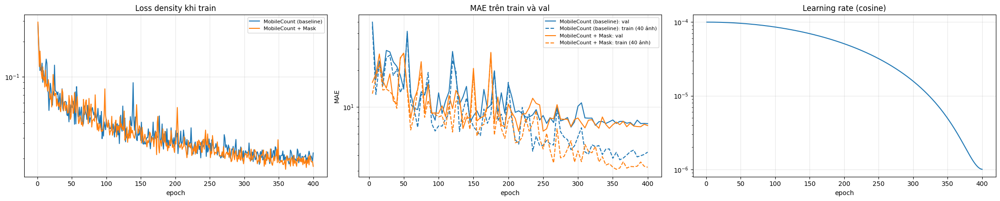

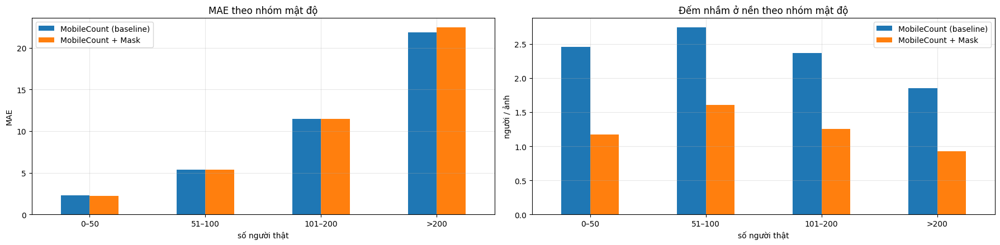

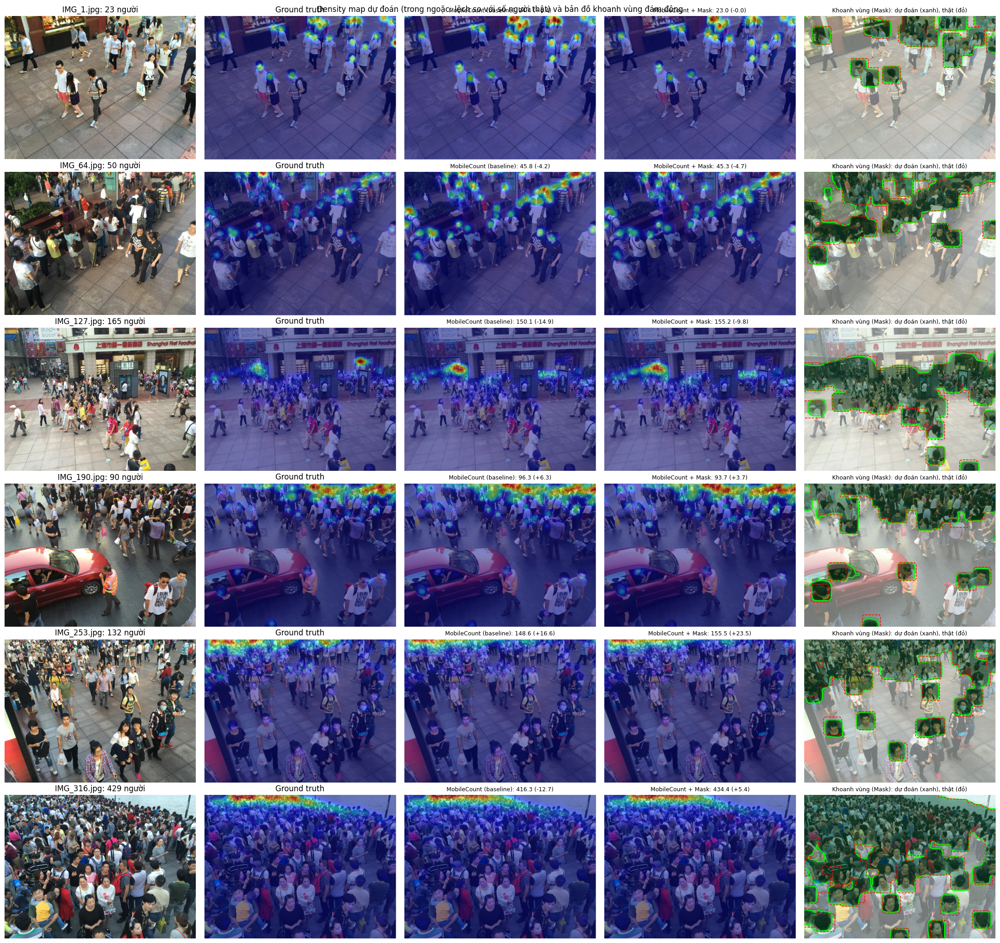

In [16]:
def save_fig(name):
    plt.savefig(os.path.join(WORK_DIR, f'final_{name}_part{PART}.png'), bbox_inches='tight')


keys = [k for k in RUN_VARIANTS if k in RESULTS]

# Hình 1: quá trình train
fig, axes = plt.subplots(1, 3, figsize=(22, 4.5))
for k in keys:
    h, l = RESULTS[k][0]['history'], VARIANTS[k]['label']
    v = h.dropna(subset=['val_MAE'])
    axes[0].plot(h['epoch'], h['loss_density'], label=l)
    line, = axes[1].plot(v['epoch'], v['val_MAE'], label=f'{l}: val')
    if 'train_MAE' in v:
        axes[1].plot(v['epoch'], v['train_MAE'], '--', color=line.get_color(), label=f'{l}: train ({TRAIN_PROBE} ảnh)')
axes[0].set(title='Loss density khi train', xlabel='epoch', yscale='log'); axes[0].legend(fontsize=8)
axes[1].set(title='MAE trên train và val', xlabel='epoch', ylabel='MAE', yscale='log'); axes[1].legend(fontsize=8)
h0 = RESULTS[keys[0]][0]['history']   # lr giống nhau ở hai model
axes[2].plot(h0['epoch'], h0['lr']); axes[2].set(title='Learning rate (cosine)', xlabel='epoch', yscale='log')
plt.tight_layout(); save_fig('curves'); plt.show()

# Hình 2: sai số theo nhóm mật độ
fig, axes = plt.subplots(1, 2, figsize=(18, 4.5))
per_bin = pd.DataFrame({VARIANTS[k]['label']: mean_preds(k).pipe(
    lambda d: d.groupby(density_bin(d['gt']), observed=False)['error'].apply(lambda e: e.abs().mean())) for k in keys})
per_bin.plot.bar(ax=axes[0], rot=0)
axes[0].set(title='MAE theo nhóm mật độ', xlabel='số người thật', ylabel='MAE')
bg_bin = pd.DataFrame({VARIANTS[k]['label']: mean_preds(k).pipe(
    lambda d: d.groupby(density_bin(d['gt']), observed=False)['bg_count'].mean()) for k in keys})
bg_bin.plot.bar(ax=axes[1], rot=0)
axes[1].set(title='Đếm nhầm ở nền theo nhóm mật độ', xlabel='số người thật', ylabel='người / ảnh')
plt.tight_layout(); save_fig('density_bins'); plt.show()

# Hình 3: density map và bản đồ khoanh vùng trên các ảnh test cố định
mask_key = next((k for k in keys if VARIANTS[k]['mask']), None)
n_cols = 2 + len(keys) + (mask_key is not None)
fig, axes = plt.subplots(len(SAMPLE_NAMES), n_cols, figsize=(4.4 * n_cols, 3.5 * len(SAMPLE_NAMES)), squeeze=False)
for row, (i, name) in zip(axes, enumerate(SAMPLE_NAMES)):
    r = test_by_name[name]
    img = Image.open(r['path']).convert('RGB')
    w, h = img.size
    gt = GT_TEST[name]
    extent = (0, gt.shape[1] * STRIDE, gt.shape[0] * STRIDE, 0)
    row[0].imshow(img); row[0].set_title(f"{name}: {len(r['points'])} người")
    row[1].imshow(img); row[1].imshow(gt, cmap='jet', alpha=0.5, extent=extent); row[1].set_title('Ground truth')
    for ax, k in zip(row[2:], keys):
        den = RESULTS[k][0]['samples'][f'den_{i}'].astype(np.float32)
        ax.imshow(img); ax.imshow(den, cmap='jet', alpha=0.5, extent=extent)
        ax.set_title(f"{VARIANTS[k]['label']}: {den.sum():.1f} ({den.sum() - len(r['points']):+.1f})", fontsize=9)
    if mask_key is not None:
        ax = row[-1]
        mask = RESULTS[mask_key][0]['samples'][f'mask_{i}'].astype(np.float32)
        ax.imshow(img)
        ax.imshow(mask, cmap='Greens', alpha=0.45, vmin=0, vmax=1, extent=extent)
        ax.contour(mask, levels=[0.5], colors='lime', linewidths=1.5, extent=extent, origin='upper')
        ax.contour(gt > MASK_THRESH, levels=[0.5], colors='red', linewidths=1, linestyles='--', extent=extent, origin='upper')
        ax.set_title('Khoanh vùng (Mask): dự đoán (xanh), thật (đỏ)', fontsize=9)
    for ax in row:
        ax.set(xlim=(0, w), ylim=(h, 0)); ax.axis('off')
plt.suptitle('Density map dự đoán (trong ngoặc: lệch so với số người thật) và bản đồ khoanh vùng đám đông')
plt.tight_layout(); save_fig('visual'); plt.show()

## 9. Bảng so sánh

Kết quả của checkpoint tốt nhất (theo val) trên toàn bộ 316 ảnh test.

| Cột | Ý nghĩa | Tốt hơn khi |
|---|---|---|
| MAE | sai số tuyệt đối trung bình của số người mỗi ảnh | thấp |
| MSE | căn bậc hai sai số bình phương trung bình (phạt nặng ảnh sai nhiều) | thấp |
| GAME1–3 | chia ảnh thành 4, 16, 64 ô và cộng sai số từng ô: đo cả việc đếm đúng chỗ | thấp |
| Đếm nhầm ở nền | số người model đặt vào chỗ cách mọi đầu người hơn 3 sigma | thấp |
| IoU mask | độ trùng giữa vùng đám đông dự đoán và thực tế (chỉ MobileCount + Mask) | cao |
| MAE epoch cuối | MAE của checkpoint ở epoch 400, để đối chiếu với checkpoint chọn theo val | thấp |
| Tham số, GMACs | kích thước và khối lượng tính toán của model (ảnh 1024×768) | thấp |
| FPS fp32 / fp16 | số ảnh 1024×768 xử lý mỗi giây (batch 1) | cao |

In [17]:
rows = {}
for k in keys:
    st = MODEL_STATS[k]
    rows[VARIANTS[k]['label']] = {**{m: fmt_ms(*mean_std(k, m)) for m in METRICS},
                                  'MAE epoch cuối': fmt_ms(*mean_std(k, 'last_MAE')),
                                  'Tham số (triệu)': f"{st['params_M']:.2f}",
                                  'GMACs': f"{st['GMACs']:.2f}" if st['GMACs'] else '–',
                                  'FPS fp32 / fp16': f"{st['FPS']:.1f} / {st['FPS_fp16']:.1f}"}
table = pd.DataFrame(rows).T
table = table.loc[:, (table != '–').any()]
table.to_csv(os.path.join(WORK_DIR, f'final_comparison_part{PART}.csv'))
print(f'Part {PART}, {len(test_recs)} ảnh test, {len(SEEDS)} seed, {GPU_NAME}.' + (' CHẠY THỬ, KHÔNG DÙNG SỐ LIỆU.' if QUICK else ''))
display(table)

Part B, 316 ảnh test, 3 seed, Tesla T4.


,MAE,MSE,GAME1,GAME2,GAME3,Đếm nhầm ở nền,IoU mask,MAE epoch cuối,Tham số (triệu),GMACs,FPS fp32 / fp16
MobileCount (baseline),9.78 ± 0.38,15.95 ± 0.32,13.04 ± 0.40,17.63 ± 0.45,23.86 ± 0.38,2.44 ± 0.30,–,9.37 ± 0.12,1.96,7.47,50.1 / 72.4
MobileCount + Mask,9.69 ± 0.87,16.04 ± 2.11,12.78 ± 0.87,17.17 ± 0.93,23.01 ± 0.78,1.31 ± 0.13,0.88 ± 0.00,8.91 ± 0.11,1.98,8.37,48.5 / 79.5
